In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['mathtext.default'] = 'regular'
import scipy.stats


# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})


# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)
    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)




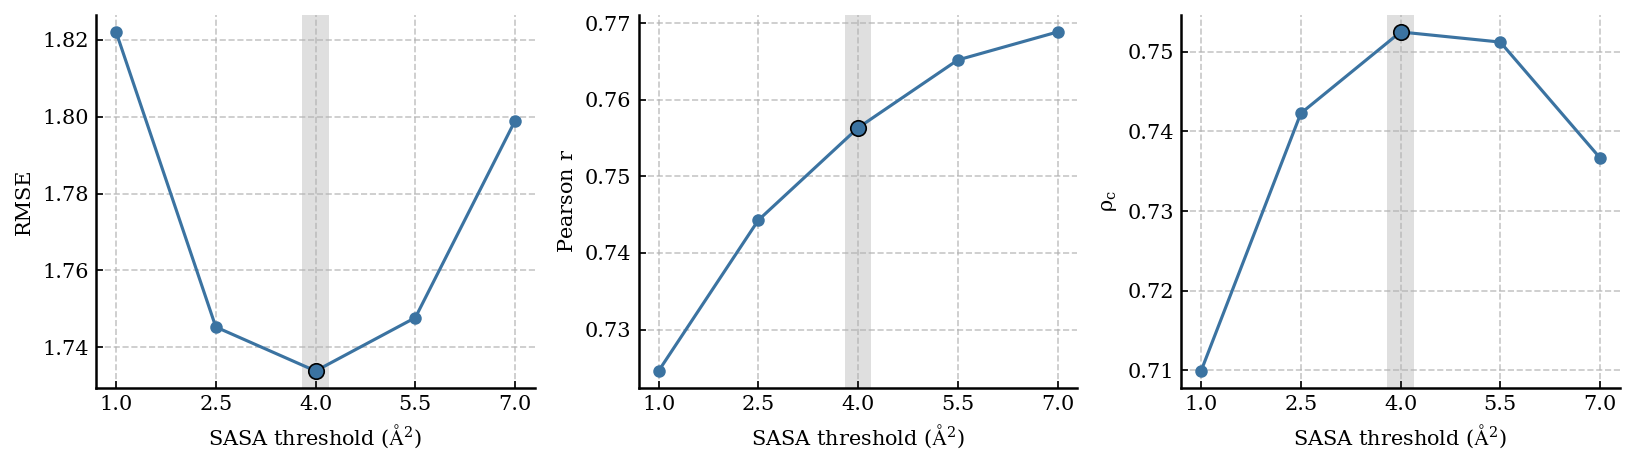

In [26]:
# Check optimal M9 SASA threshold
sasa_thresholds = [1.0, 2.5, 4.0, 5.5, 7.0]

M9_rmse = []
M9_pearsonr = []
M9_ccc = []

for threshold in sasa_thresholds:
    data = pd.read_csv(
        f"../../output_results/data_EXP_vs_SIM_M9_sasa_{threshold}Ang.csv",
        index_col=0
    )

    x = np.log10(data['EXP PF'])
    y = np.log10(data['SIM PF'])

    M9_rmse.append(RMSE(x, y))
    M9_pearsonr.append(scipy.stats.pearsonr(x, y)[0])
    M9_ccc.append(calc_ccc(x, y))


# --------------------------------------------------
# Plot statistics
# --------------------------------------------------
COLOR = "#3B73A1"
BEST_CUTOFF = 4.0

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

stats = [M9_rmse, M9_pearsonr, M9_ccc]
ylabels = [
    r"RMSE",
    r"Pearson $r$",
    r"$\rho_c$"
]

for ax, values, ylabel in zip(axes, stats, ylabels):

    # Highlight selected SASA cutoff
    ax.axvspan(
        3.8,
        4.2,
        color='grey',
        alpha=0.25,
        linewidth=0,
        zorder=0
    )

    ax.plot(
        sasa_thresholds,
        values,
        marker='o',
        color=COLOR,
        linewidth=1.5,
        markersize=5,
        zorder=2
    )

    # Emphasise the point at 4.0 Å²
    best_index = sasa_thresholds.index(BEST_CUTOFF)
    ax.scatter(
        BEST_CUTOFF,
        values[best_index],
        s=55,
        facecolor=COLOR,
        edgecolor='black',
        linewidth=0.8,
        zorder=3
    )

    ax.set_xlabel(r"SASA threshold ($\mathrm{\AA}^2$)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sasa_thresholds)

    # Remove top and right axis lines and ticks
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(
        axis='both',
        which='both',
        top=False,
        right=False
    )

plt.tight_layout()
plt.savefig('M9_sasa_scan.pdf', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_564009/2903892940.py:57: UserWarning: The following kwargs were not used by contour: 'rasterized'
  cf = ax.contourf(


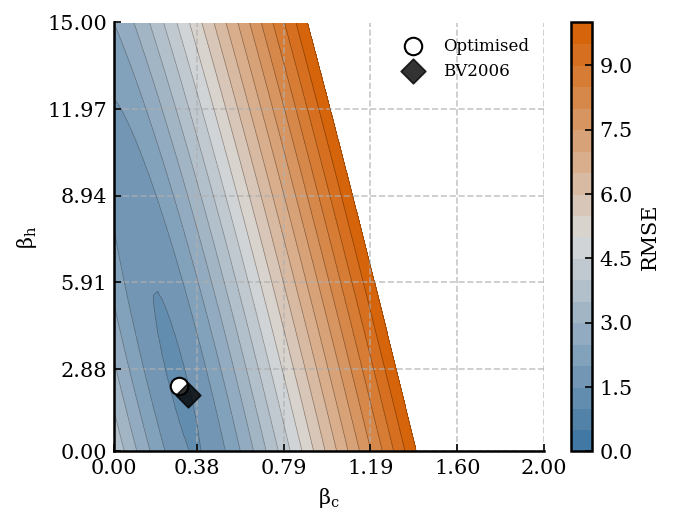

In [30]:
# BV2006 optimisation
from matplotlib.colors import LinearSegmentedColormap

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"   # deep muted blue
COLOR1 = "#D55E00"   # vermillion
COLOR2 = "#D9D9D9"   # light grey

# --------------------------------------------------
# Load optimisation matrix
# --------------------------------------------------
rmse_matrix = pd.read_csv(
    '../../output_results/RMSE_optimisation_matrix_BV2006_PF_Nguyen_2018.csv',
    index_col=0
)

beta_c_vals = np.array(rmse_matrix.index).astype(float)
beta_h_vals = np.array(rmse_matrix.columns).astype(float)
m = np.array(rmse_matrix)

# --------------------------------------------------
# Find optimum and original parameter positions
# --------------------------------------------------
x_min = np.where(m == np.min(m))[0][0]
y_min = np.where(m == np.min(m))[1][0]

# Original BV2006 parameters
org_beta_c = 0.35
org_beta_h = 2.0

x_org = np.where(
    np.abs(beta_c_vals - org_beta_c) == np.min(np.abs(beta_c_vals - org_beta_c))
)[0][0]

y_org = np.where(
    np.abs(beta_h_vals - org_beta_h) == np.min(np.abs(beta_h_vals - org_beta_h))
)[0][0]

# --------------------------------------------------
# Custom colour gradient
# low RMSE = blue, intermediate = grey, high = vermillion
# --------------------------------------------------
cmap = LinearSegmentedColormap.from_list(
    "rmse_gradient",
    [COLOR3, COLOR2, COLOR1]
)

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(4.6, 3.6))

levels = np.arange(0, 10.5, 0.5)

cf = ax.contourf(
    np.arange(len(beta_c_vals)),
    np.arange(len(beta_h_vals)),
    m.T,
    levels=levels,
    cmap=cmap,
    vmin=0,
    vmax=10,
    rasterized=True
)

# Optional contour lines for readability
ax.contour(
    np.arange(len(beta_c_vals)),
    np.arange(len(beta_h_vals)),
    m.T,
    levels=levels,
    colors='black',
    linewidths=0.35,
    alpha=0.35
)

# --------------------------------------------------
# Mark optimised and original parameters
# --------------------------------------------------
ax.scatter(
    x_min,
    y_min,
    s=70,
    facecolor='white',
    edgecolor='black',
    linewidth=1.0,
    zorder=20,
    label='Optimised'
)

ax.scatter(
    x_org,
    y_org,
    s=70,
    facecolor='black',
    edgecolor='black',
    linewidth=0.8,
    marker='D',
    alpha=0.8,
    zorder=20,
    label='BV2006'
)

# --------------------------------------------------
# Axes labels and ticks
# --------------------------------------------------
ax.set_xlabel(r'$\beta_c$')
ax.set_ylabel(r'$\beta_h$')

tick_indices_x = np.linspace(0, len(beta_c_vals) - 1, 6, dtype=int)
tick_indices_y = np.linspace(0, len(beta_h_vals) - 1, 6, dtype=int)

ax.set_xticks(tick_indices_x)
ax.set_xticklabels([f"{beta_c_vals[i]:.2f}" for i in tick_indices_x])

ax.set_yticks(tick_indices_y)
ax.set_yticklabels([f"{beta_h_vals[i]:.2f}" for i in tick_indices_y])

# --------------------------------------------------
# Style to match previous plots
# --------------------------------------------------
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='both', top=False, right=False)

cbar = plt.colorbar(cf, ax=ax)
cbar.set_label('RMSE')

ax.legend(fontsize=8, frameon=False, loc='best')

plt.tight_layout()
plt.savefig('RMSE_matrix_BV2006_optimisation.pdf', dpi=300, bbox_inches='tight')
plt.show()

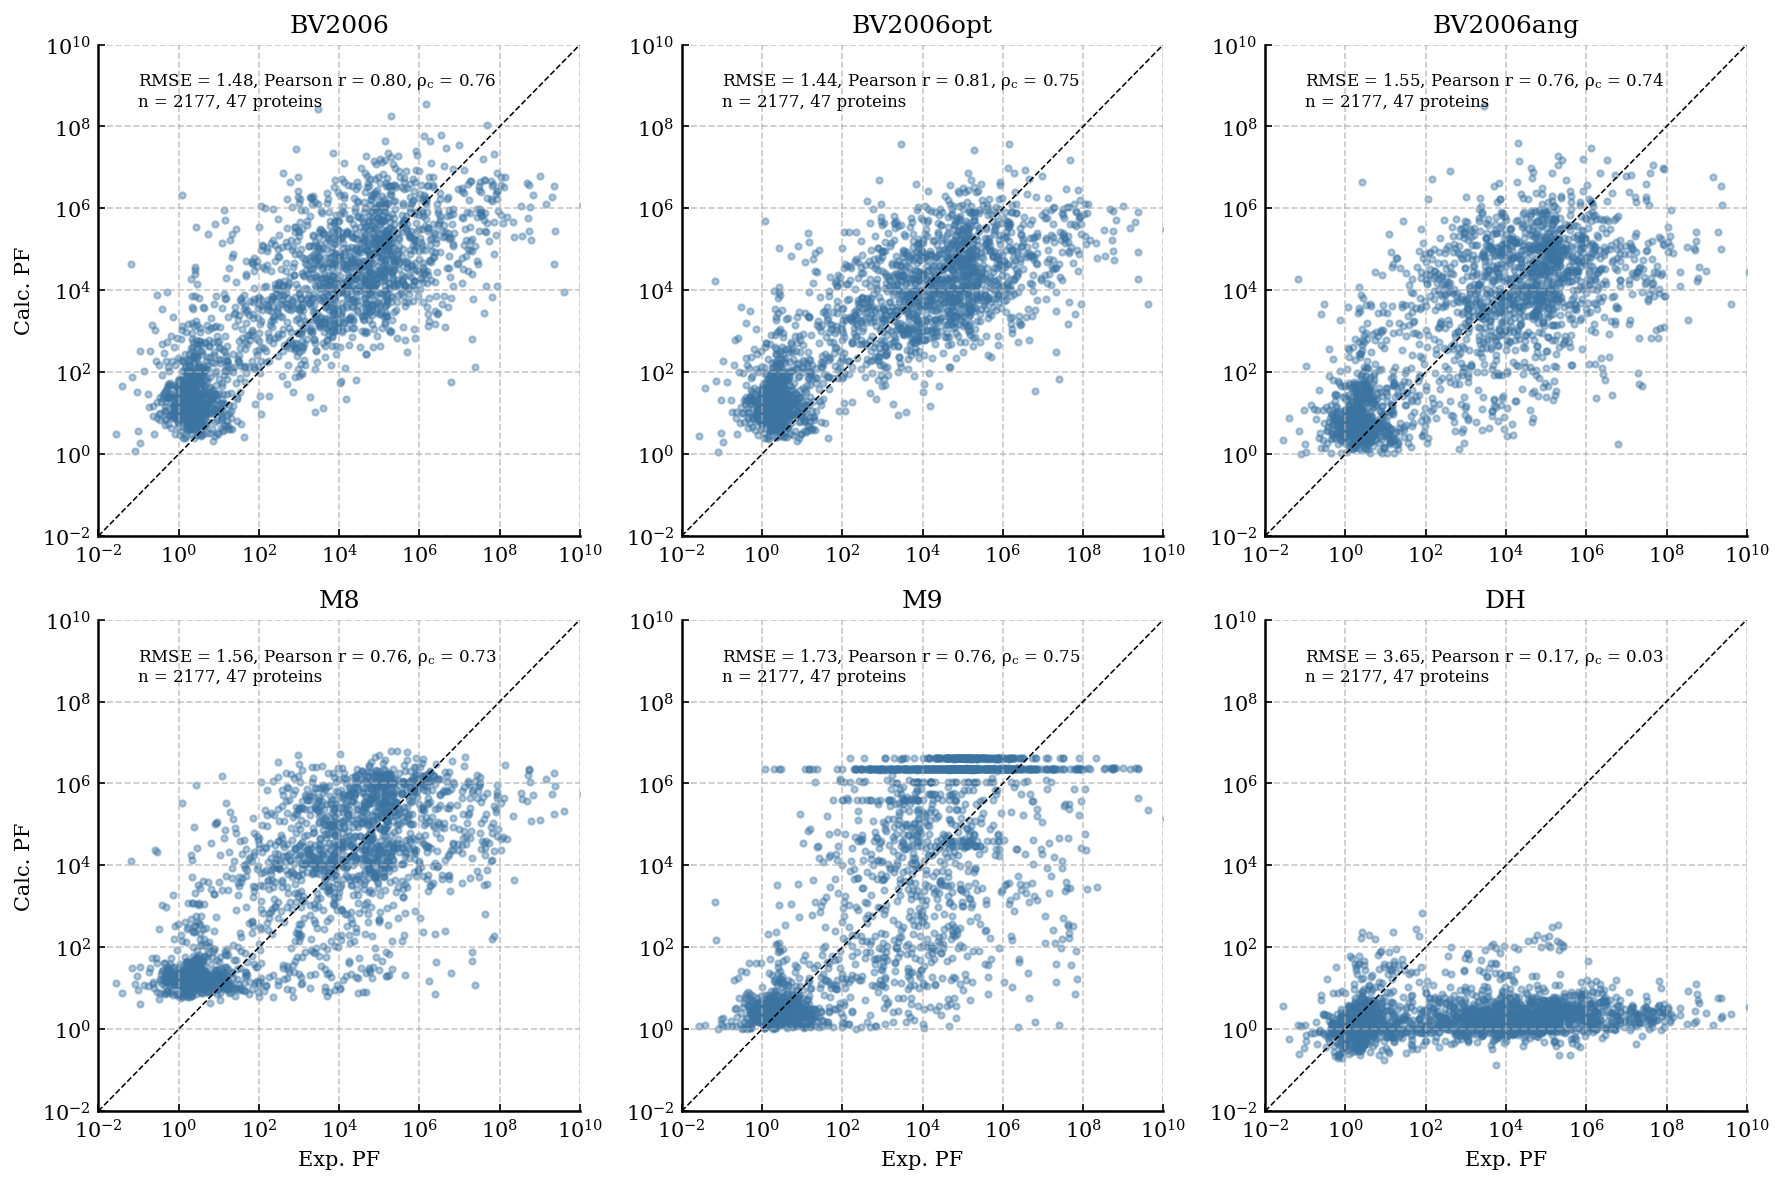

In [25]:
filenames = [
    'data_EXP_vs_SIM_BV2006_default_PF_Nguyen_2018',
    'data_EXP_vs_SIM_BV2006_optimised_betac_0.30_betah_2.27_PF_Nguyen_2018',
    'data_EXP_vs_SIM_BV2006ang_optimised_betac_0.89_betah_4.39_PF_Nguyen_2018',
    'data_EXP_vs_SIM_M8preavg_optimised',
    'data_EXP_vs_SIM_M9_sasa_4.0Ang',
    'data_EXP_vs_SIM_DHonly_PF_Nguyen_2018'
]

models = [
    'BV2006',
    'BV2006opt',
    'BV2006ang',
    'M8',
    'M9',
    'DH'
]

datasets = [
    pd.read_csv(f"../../output_results/{file}.csv", index_col=0)
    for file in filenames
]

# Make a grid of subplots (2 rows × 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, data, model_name in zip(axes, datasets, models):

    # ---- Scatter plot ----
    ax.scatter(
        data['EXP PF'],
        data['SIM PF'],
        color='#3B73A1',
        alpha=0.4,
        s=9,
        rasterized=True
    )

    # ---- Stats ----
    log_exp = np.log10(data['EXP PF'])
    log_sim = np.log10(data['SIM PF'])

    r = scipy.stats.pearsonr(log_exp, log_sim)[0]
    rmse = RMSE(log_exp, log_sim)
    ccc = calc_ccc(log_exp, log_sim)

    proteins = np.unique(np.array(data['Protein']))
    n = len(data)

    # ---- Identity line ----
    x = np.linspace(1e-2, 1e10, 200)
    ax.plot(
        x,
        x,
        color='black',
        linestyle='dashed',
        linewidth=0.75
    )

    # ---- Log scaling and limits ----
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10)
    ax.set_ylim(1e-2, 1e10)

    # ---- Remove top and right axis lines and ticks ----
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(
        axis='both',
        which='both',
        top=False,
        right=False
    )

    # ---- Labels only on left and bottom subplots ----
    if ax in axes[3:]:
        ax.set_xlabel("Exp. PF")

    if ax in axes[::3]:
        ax.set_ylabel("Calc. PF")

    # ---- Title ----
    ax.set_title(model_name)

    # ---- Text annotations ----
    ax.text(
        1e-1,
        1e9,
        rf"RMSE = {rmse:.2f}, Pearson $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}",
        fontsize=8
    )

    ax.text(
        1e-1,
        10**8.5,
        f"n = {int(n)}, {len(proteins)} proteins",
        fontsize=8
    )

# Remove any unused subplots
for j in range(len(datasets), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(
    'HDX_norew_models.pdf',
    dpi=300
)
plt.show()